In [1]:
%load_ext autoreload
%autoreload 2
import torch

In [2]:
import captum
from captum.attr import IntegratedGradients, Occlusion, LayerGradCam, LayerAttribution, GuidedGradCam, Saliency, DeepLift, GuidedBackprop, InputXGradient
from matplotlib.colors import LinearSegmentedColormap
from captum.attr import visualization as viz
import matplotlib.pyplot as plt


In [3]:
from pytorch_grad_cam import GradCAM, \
    ScoreCAM, \
    GradCAMPlusPlus, \
    AblationCAM, \
    XGradCAM, \
    EigenCAM, \
    EigenGradCAM, \
    LayerCAM, \
    FullGrad, \
    GradCAMElementWise
from pytorch_grad_cam import GuidedBackpropReLUModel
from pytorch_grad_cam.utils.image import show_cam_on_image, \
    preprocess_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import warnings


In [35]:

import os
import torch.backends.cudnn as cudnn
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import time
from datetime import datetime 
import pdb
import yaml
import sys
import glob
import shutil
import tqdm

sys.path.append('../../MARS')
import MARS.run_lars.utils
from MARS.run_lars.dataset import get_datasets, dataset_center
from MARS.run_lars.utils import model_prediction, my_model, model_prediction_dual_mipview, my_model_feat_fusion

def load_config():
    if len(sys.argv) < 2:
        print("Usage: python script.py <config.yaml>")
        sys.exit(1)

    config_path = sys.argv[1]
    with open(config_path, "r") as f:
        config = yaml.safe_load(f)
    return config

def load_config_notebook():
    config = '/gpfs/home/kn2347/MARS/MARS/scripts/run_lars/predictions/2D_all_seeds_prediction/config.yaml'
    with open(config, "r") as f:
        config_data = yaml.safe_load(f)
    return config_data

def save_copy_of_config(filename):
    config_path = sys.argv[1]
    if not os.path.exists(args["output"]):
        os.makedirs(args["output"])

    dest_path = os.path.join(args["output"], filename)
    shutil.copyfile(config_path, dest_path)
    print(f"Configuration file copied to {dest_path}")

def set_defaults_config():
    default_dict = {
        'postfilter_fwhm_xy_mm': None,
        'normalize_mean': None,
        'normalize_std': None,
        'combine_mipviews': None
    }

    for key, value in default_dict.items():
        if key not in args:
            args[key] = value

# Get user input
global args
args = load_config_notebook()
set_defaults_config()

model_path_pattern = args['model_path_pattern']
model_paths = glob.glob(model_path_pattern)
print(f"Found {len(model_paths)} model files matching the pattern.")

transform_fn = None # can change this later

# Create output directory if it doesn't exist
if not os.path.exists(args["output"]):
    os.makedirs(args["output"])

# save config file
t0 = time.time()
config_outname = "config_" + datetime.today().strftime('%Y-%m-%d_%H:%M:%S') + ".yaml"
#save_copy_of_config(config_outname)

# for test
args['dataset_type'] = 'test'
args["data_path_datafiles"] = '/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/test_df.csv'


for i, chpnt in enumerate(model_paths): 
    print('Model {}...'.format(i))

    
    # create the model
    if args['combine_mipviews'] is not None:
        model = model_prediction_dual_mipview(chpnt)
    else:
        model = model_prediction(chpnt, arch='resnet34')
    model.cuda()
    
    cudnn.benchmark = True

    # Set datasets
    dset = get_datasets(dataset_type=args["dataset_type"], 
                        norm=args["normalize"], transform=transform_fn, 
                        data_path_img = args["data_path_img"], data_path = args["data_path_datafiles"],
                        postfilter_fwhm_xy_mm=args["postfilter_fwhm_xy_mm"], 
                        normalize_mean=args.get("normalize_mean", None), normalize_std=args.get("normalize_std", None),
                        combine_mipviews=args.get("combine_mipviews", None))
    print('  dataset size: {}'.format(len(dset.df)))

    
def predict(dset, model):
    # Set loaders
    loader = torch.utils.data.DataLoader(dset, batch_size=args["batch_size"], shuffle=False, num_workers=args["workers"])
        
    # Evaluate on test data
    probs, feats = test(loader, model)
    out = dset.df.copy().reset_index(drop=True)
    out['probs'] = probs
    feats = pd.DataFrame(feats, columns=['F{}'.format(x) for x in range(1,args["nfeat"]+1)])
    out = pd.concat([out, feats], axis=1)
    return out

def test(loader, model):
    # Set model in test mode
    model.eval()
    # Initialize probability vector
    probs = torch.FloatTensor(len(loader.dataset)).cuda()
    # Initialize features
    feats = np.empty((len(loader.dataset),args["nfeat"]))
    # Loop through batches
    with torch.no_grad():
        # use tqdm to loop over dataloader
        for i, (input, _) in enumerate(tqdm.tqdm(loader)):            
            # print('Batch: [{}/{}]'.format(i+1, len(loader)))
            ## Copy batch to GPU
            input = input.cuda()
            ## Forward pass
            f, output = model.forward_feat(input)
            output = F.softmax(output, dim=1)
            ## Features
            feats[i*args["batch_size"]:i*args["batch_size"]+input.size(0),:] = f.detach().cpu().numpy()
            ## Clone output to output vector
            probs[i*args["batch_size"]:i*args["batch_size"]+input.size(0)] = output.detach()[:,1].clone()

    return probs.cpu().numpy(), feats

all_model_outputs = [None] * 10
def register_indexed_hook(model, layeridx, index):
    """Registers the hook and binds it to a specific index in the list."""
    def indexed_hook(module, input, output):
        # Store the output in the list at the position corresponding to the model's index
        all_model_outputs[index] = output.detach()
        pass
    
    layer = model.features[layeridx][2].conv2
    return layer.register_forward_hook(indexed_hook)

Found 10 model files matching the pattern.
Model 0...
  dataset size: 1184
Model 1...
  dataset size: 1184
Model 2...
  dataset size: 1184
Model 3...
  dataset size: 1184
Model 4...
  dataset size: 1184
Model 5...
  dataset size: 1184
Model 6...
  dataset size: 1184
Model 7...
  dataset size: 1184
Model 8...
  dataset size: 1184
Model 9...
  dataset size: 1184


In [12]:
#model_path_pattern = f'/gpfs/data/mayerhoeferlab/projects/myeloma/results/train/train_all_seeds_combine_mipviews_11-8-25/checkpoint_seed*_run*_best.pth'

model_path_pattern = f'/gpfs/data/mayerhoeferlab/projects/myeloma/results/train/train_all_seeds_11-8-25/checkpoint_seed*_run*_best.pth'
#rt = f'/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_dual_mipview_all_seeds_prediction'
rt = f'/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction'
dataset_type = 'test'
model_paths = glob.glob(model_path_pattern)
#args['combine_mipviews'] = 'feature_concatenation'
args['postfilter_fwhm_xy_mm'] = 6.4
models_list = []

for x in sorted(model_paths):
    if args['combine_mipviews'] is not None:
        model = model_prediction_dual_mipview(x)
    else:
        model = model_prediction(x, arch='resnet34')
    models_list.append(model.cuda().eval())

In [36]:
dset = get_datasets(dataset_type=args["dataset_type"], 
                        norm=args["normalize"], transform=transform_fn, 
                        data_path_img = args["data_path_img"], data_path = args["data_path_datafiles"],
                        postfilter_fwhm_xy_mm=args["postfilter_fwhm_xy_mm"], 
                        normalize_mean=args.get("normalize_mean", None), normalize_std=args.get("normalize_std", None),
                        combine_mipviews=args.get("combine_mipviews", None))

In [14]:

dfs_list = []
for i in range(10):
    dfr = pd.read_csv(os.path.join(rt, dataset_type, f'pred_{dataset_type}_{i}.csv'))
    col_list = ['filepath', 'PET_jco', 'PET_imwg', 'probs']
    if 'mipview' in dfr.columns: col_list.append('mipview')
    dfr = dfr[col_list]
    dfr['model_number'] = i
    dfs_list.append(dfr)
model_probabilities = pd.concat(dfs_list)
model_probabilities.rename({'filepath': 'accession'}, axis=1, inplace=True)

In [19]:
model_probabilities[model_probabilities['accession'] == 19390745]

,accession,PET_jco,PET_imwg,probs,mipview,model_number
256,19390745,1.0,1.0,1.000000,cor,0
848,19390745,1.0,1.0,1.000000,sag,0
256,19390745,1.0,1.0,1.000000,cor,1
848,19390745,1.0,1.0,1.000000,sag,1
256,19390745,1.0,1.0,1.000000,cor,2
848,19390745,1.0,1.0,1.000000,sag,2
256,19390745,1.0,1.0,1.000000,cor,3
848,19390745,1.0,1.0,0.999999,sag,3
256,19390745,1.0,1.0,0.999997,cor,4
848,19390745,1.0,1.0,0.999994,sag,4


In [ ]:
# only use accessions in the desired split
split = pd.read_pickle('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/splits/train_val_test_split.pkl')
df = model_probabilities[model_probabilities['accession'].isin(split[dataset_type])]
#binarization_threshold = 0.5 # for now

uses_mipview = 'mipview' in model_probabilities.columns

col_list = ['accession', 'probs', 'model_number']
if uses_mipview: col_list.append('mipview')
df = df[col_list]

filt_col = ['accession']
if uses_mipview: filt_col.append('mipview')
df = df.groupby(filt_col).agg({'probs': 'mean'}).reset_index()

target = pd.read_excel('/gpfs/data/mayerhoeferlab/projects/myeloma/curated_status/Myeloma_master_ref_15_08_2025.xlsx')
target = target.rename(columns={'ACC':'accession','PET-jco':'PET_jco','PET-imwg':'PET_imwg'})
target = target[['accession', 'PET_jco', 'PET_imwg']]

# merge to get labels
col_list = ['accession', 'probs', 'PET_jco', 'PET_imwg']
if uses_mipview: col_list.append('mipview')
merged = pd.merge(df, target[['accession', 'PET_jco', 'PET_imwg']] , on='accession', how='left')
merged = merged[col_list]

# exclude cases where there was no label available
merged = merged.dropna(subset = ['PET_jco'], axis='index')

# also exclude cases where the label is 2 (just for now)
merged = merged[merged['PET_jco'] != 2]

merged_before_drop_mipview = merged.copy()
# average probs across mipview
merged = merged.groupby(['accession']).agg({'probs': ['mean', 'max', 'min'], 'PET_jco': 'first', 'PET_imwg': 'first'}).reset_index()
merged.columns = [' '.join(col).strip() for col in merged.columns.values]
merged['mip_difference'] = merged['probs max'] - merged['probs min']
merged = merged.rename({'probs mean': 'probs', 'PET_jco first': 'PET_jco', 'PET_imwg first': 'PET_imwg'}, axis=1)
merged = merged.drop(['probs max', 'probs min'], axis=1)
merged['difference'] = abs(merged['probs'] - merged['PET_jco'])

merged['binarized_prediction']  = (merged['probs'] >= binarization_threshold).astype(int)
merged = merged[['accession', 'probs', 'difference', 'mip_difference', 'binarized_prediction', 'PET_jco', 'PET_imwg']]
merged = merged.sort_values(by=['accession'])

In [20]:
# pick examples that maximize probs - PET_jco:
    # 1. false positive: PET_jco=0
    # 2. false negative PET_jco=1

merged = merged.sort_values(by='difference', ascending=True) # sort by smallest difference first

num_to_select = 5
false_positives = merged[merged['PET_jco'] == 0].tail(num_to_select)
false_negatives = merged[merged['PET_jco'] == 1].tail(num_to_select)
true_positives = merged[merged['PET_jco'] == 1].head(20)

# next, pick examples where the predicted probability was closest to binarization_threshold (most uncertain)
merged['certainty'] = abs(merged['probs'] - binarization_threshold)
merged = merged.sort_values(by='certainty', ascending=True) # sort by smallest certainty first
most_uncertain = merged.head(10)

# add a column to most_uncertain to indicate the type of example (TP, TN, FP, FN) using probs and PET_jco
most_uncertain['type'] = most_uncertain.apply(lambda row: 'TP' if (row['probs'] >= binarization_threshold and row['PET_jco'] == 1) else ('TN' if (row['probs'] < binarization_threshold and row['PET_jco'] == 0) else ('FP' if (row['probs'] >= binarization_threshold and row['PET_jco'] == 0) else 'FN')), axis=1)

# next, pick random examples
random_examples = merged.sample(n = 10, replace = False, random_state = 2025)
random_examples['type'] = random_examples.apply(lambda row: 'TP' if (row['probs'] >= binarization_threshold and row['PET_jco'] == 1) else ('TN' if (row['probs'] < binarization_threshold and row['PET_jco'] == 0) else ('FP' if (row['probs'] >= binarization_threshold and row['PET_jco'] == 0) else 'FN')), axis=1)

# also pick some examples where the mip difference is maximized
if uses_mipview:
    merged = merged.sort_values(by='mip_difference', ascending=False)
    mip_difference_examples = merged.head(10)
    mip_difference_examples['type'] = mip_difference_examples.apply(lambda row: 'TP' if (row['probs'] >= binarization_threshold and row['PET_jco'] == 1) else ('TN' if (row['probs'] < binarization_threshold and row['PET_jco'] == 0) else ('FP' if (row['probs'] >= binarization_threshold and row['PET_jco'] == 0) else 'FN')), axis=1)
else:
    mip_difference_examples = None

/tmp/ipykernel_3662037/2482009203.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  most_uncertain['type'] = most_uncertain.apply(lambda row: 'TP' if (row['probs'] >= binarization_threshold and row['PET_jco'] == 1) else ('TN' if (row['probs'] < binarization_threshold and row['PET_jco'] == 0) else ('FP' if (row['probs'] >= binarization_threshold and row['PET_jco'] == 0) else 'FN')), axis=1)


In [20]:
default_cmap = LinearSegmentedColormap.from_list('custom blue',
                                                 [(0, '#ffffff'),
                                                  (1, '#0000ff')], N=256)

cmap_2 = LinearSegmentedColormap.from_list('',
                                                 [(0, "#ff0000"),
                                                  (0.5, "#FFFFFF"),
                                                  (1, '#0000ff')], N=256)

In [21]:
def dataset_tensor_to_rgb_img(tensor):
    # tensor should have shape (C, 310, 310)
    nparray = torch.flatten(tensor, start_dim=0, end_dim=1).numpy() # (C*310,310)
    nparray = np.stack((nparray,)*3, axis=2) # (C*310,310,3) 
    nparray = (nparray - nparray.min()) / (nparray.max() - nparray.min())
    nparray = nparray * 255
    nparray = nparray.astype(np.uint8)
    return nparray

In [29]:
dset.df[dset.df['accession'] == 19390745]

,filepath,filename,filename_header,fullfile,patient_age,patient_sex,patient_weight,smoking_status,accession,study_uid,...,tracer,tracer_injection_time,tracer_dose,tracer_halflife,image_filter,contrast_route,axial_fov,PET_jco,PET_imwg,mipview


In [22]:
def calculate_interpretability_for_study(accession_id, mipview, label_number, type='IntegratedGradients', layer_to_iterate = None, device='cuda', model_to_use=model,
                                    model_idx = None):
    pred_label_idx = label_number
    rr = dset.df[(dset.df['accession'] == accession_id) & (mipview is None or dset.df['mipview'] == mipview)]
    idx = rr.index[0]
    assert len(rr) == 1, "accession_id not found or not unique"
    rr = dset[idx][0] # get the tensor
    rgb_img = dataset_tensor_to_rgb_img(rr) # convert to rgb image
    input_shape_per_batch = rr.shape
    predprob = merged_before_drop_mipview[(merged_before_drop_mipview['accession'] == accession_id) & (mipview is None or merged_before_drop_mipview['mipview'] == mipview)]['probs'].values[0]
    if model_idx is not None:
        predprob = model_probabilities[(model_probabilities['accession'] == accession_id) & (model_probabilities['model_number'].isin(model_idx)) & (mipview is None or model_probabilities['mipview'] == mipview)]['probs']
        predprob = predprob.mean()
        #assert len(predprob) == 1, "Prediction probability not found or not unique"
    true_label = merged_before_drop_mipview[(merged_before_drop_mipview['accession'] == accession_id) & (mipview is None or merged_before_drop_mipview['mipview'] == mipview)]['PET_jco'].values[0]
    inp_tensor = rr.unsqueeze(0).to(device)
    attribution_list = []
    inp_tensor.requires_grad=True
    for model_this_idx in model_idx:
        model_to_use = models_list[model_this_idx]
        model_to_use.cuda().eval()
        if type == 'pytorch-gradcam':
            assert mipview is not None # dual-mipview cannot be used with gradcam because it averaging gradients in the channels is meaningless
            targets = [ClassifierOutputTarget(label_number)]
            
            with GradCAM(model=model_to_use, target_layers=[layer_to_iterate]) as cam:
                grayscale_cam = cam(input_tensor=inp_tensor, targets=targets)

            attributions = np.reshape(grayscale_cam, (input_shape_per_batch[0] * input_shape_per_batch[1], input_shape_per_batch[2])) # remove channel dimension by flattening, for visualization against rgb_img
        
        elif type == 'IntegratedGradients':
            obj = IntegratedGradients(model_to_use)
            attributions = obj.attribute(inp_tensor, target=pred_label_idx, n_steps=200)
        elif type == 'LayerGradCam':
            obj = LayerGradCam(model_to_use, layer_to_iterate)
            attributions = obj.attribute(inp_tensor, target=pred_label_idx)
            attributions = LayerAttribution.interpolate(attributions, inp_tensor.shape[2:])
        elif type == 'GuidedGradCam':
            obj = GuidedGradCam(model_to_use, layer_to_iterate)
            try:
                attributions = obj.attribute(inp_tensor, target=pred_label_idx)
            except Exception as e:
                print(f"Error in GuidedGradCam attribution: {e}")
                print(model_this_idx)
                attributions = torch.zeros_like(inp_tensor)
        elif type == 'Occlusion':
            obj = Occlusion(model_to_use)
            attributions = obj.attribute(inp_tensor, target=pred_label_idx,
                                        sliding_window_shapes=(1, 8, 8), 
                                        strides=(1, 8, 8), 
                                        baselines=0)
        elif type=='Saliency':
            obj = Saliency(model_to_use)
            attributions = obj.attribute(inp_tensor, target=pred_label_idx)
        elif type=='InputXGradient':
            obj = InputXGradient(model_to_use)
            attributions = obj.attribute(inp_tensor, target=pred_label_idx)
        elif type=='GuidedBackprop':
            obj = GuidedBackprop(model_to_use)
            attributions = obj.attribute(inp_tensor, target=pred_label_idx)
        
        attribution_list.append(attributions)

    attributions = torch.mean(torch.stack(attribution_list), dim=0)
    attributions = attributions.cpu().detach().squeeze().view(input_shape_per_batch)
    if attributions.shape[0] != 1:
        # flatten dimension to match dims of rgb_img for visualization
        attributions = torch.flatten(attributions, start_dim=0, end_dim=1)
        attributions = attributions.unsqueeze(0)
    attributions = attributions.numpy()

    return (np.uint8(255 - rgb_img), attributions, predprob)

def visualize_interpretability(rgb_img, attributions, predprob, fig, axs, type='IntegratedGradients', alpha=0.7, i1=None, i2=None):
    cmap = None
    if type in ['IntegratedGradients', 'LayerGradCam', 'GuidedGradCam']:
        cmap = default_cmap
        sign = 'positive'
    elif type=='GuidedBackprop':
        cmap = cmap_2
        sign='all'
    else:
        cmap = None
        sign='all'
    
    method_viz = 'heat_map' if type=='GuidedBackprop' else 'blended_heat_map'
    if i1 is None:
        if type=='pytorch-gradcam':
            rgb_img_norm = rgb_img / 255.0
            visualization = show_cam_on_image(rgb_img_norm, attributions, use_rgb=True, image_weight = 0.5)
            axs.imshow(visualization)
            axs.axis('off')
            return
        
        bd = viz.visualize_image_attr(
            np.transpose(attributions, (1,2,0)),
            rgb_img,
            method=method_viz,
            cmap=cmap,
            show_colorbar=False,
            sign=sign,
            title='',
            alpha_overlay = alpha,
            plt_fig_axis=(fig, axs), use_pyplot=False)
    else:
        A1 = attributions[:, :attributions.shape[1]//2, :]
        A2 = attributions[:, attributions.shape[1]//2 : -1, :]
        bd = viz.visualize_image_attr(
            np.transpose(A1, (1,2,0)),
            rgb_img[:rgb_img.shape[0]//2, :, :],
            method=method_viz,
            cmap=cmap,
            show_colorbar=False,
            sign=sign,
            title='',
            alpha_overlay = alpha,
            plt_fig_axis=(fig, axs[i1[0], i1[1]]), use_pyplot=False)
        bd = viz.visualize_image_attr(
            np.transpose(A2, (1,2,0)),
            rgb_img[rgb_img.shape[0]//2 : -1, :, :],
            method=method_viz,
            cmap=cmap,
            show_colorbar=False,
            sign=sign,
            title='',
            alpha_overlay = alpha,
            plt_fig_axis=(fig, axs[i2[0], i2[1]]), use_pyplot=False)
        

    
    assert rgb_img.min() >= 0 and rgb_img.max() <= 255 

In [24]:
acc_list = []
label_list = []
lab_list = []
true_label = []
for i, grp in enumerate([true_positives]):
    # do it for one label
    acc_list.extend(grp['accession'].tolist())
    label_list.extend( (grp['probs'] >= binarization_threshold).astype(int).tolist())
    lab_list.extend(['TP']*len(grp))
    true_label.extend(grp['PET_jco'].astype(int).tolist())

for i, grp in enumerate([false_positives, false_negatives]):
    # do it for both labels
    acc_list.extend(grp['accession'].tolist())
    acc_list.extend(grp['accession'].tolist())
    label_list.extend( (grp['probs'] >= binarization_threshold).astype(int).tolist())
    label_list.extend((grp['probs'] < binarization_threshold).astype(int).tolist())
    lab_list.extend(['FP']*len(grp)*2 if i==0 else ['FN']*len(grp)*2)
    true_label.extend(grp['PET_jco'].astype(int).tolist()*2)

for i, grp in enumerate([most_uncertain, random_examples]):
    # do it for both labels
    acc_list.extend(grp['accession'].tolist())
    acc_list.extend(grp['accession'].tolist())
    label_list.extend( (grp['probs'] >= binarization_threshold).astype(int).tolist())
    label_list.extend((grp['probs'] < binarization_threshold).astype(int).tolist())
    lab_list.extend(grp['type'].tolist()*2)
    true_label.extend(grp['PET_jco'].astype(int).tolist()*2)

dfo_prep = pd.DataFrame({'accession': acc_list, 'label': label_list, 'type': lab_list, 'true_label': true_label})

In [23]:
dfo_prep = pd.DataFrame({'accession': [19390745, 6487513], 'label': [1, 1], 'type': ['TP', 'FP'], 'true_label': [1, 0]})

In [25]:
# register hooks

#for i, model in enumerate(models_list):
#    register_indexed_hook(model, layer_idx, i)

In [45]:
targs = [1, 1]
overall_list = []
for i, acc in enumerate([19390745, 6487513]):
    rr = dset.df[(dset.df['accession'] == acc) & (dset.df['mipview'] == 'cor')]
    idx = rr.index[0]
    assert len(rr) == 1, "accession_id not found or not unique"
    rr = dset[idx][0] # get the tensor
    rgb_img = dataset_tensor_to_rgb_img(rr) # convert to rgb image
    input_shape_per_batch = rr.shape

    inp_tensor = rr.unsqueeze(0).to('cuda')

    attribution_list = []
    inp_tensor.requires_grad=True
    for model_this_idx in range(10):
        model_to_use = models_list[model_this_idx]
        model_to_use.cuda().eval()
        target_layer = model_to_use.features[4][2].conv2

        obj = GuidedGradCam(model_to_use, target_layer)
        #print(inp_tensor)
        try:
            attributions = obj.attribute(inp_tensor, target=targs[i])
        except Exception as e:
            print(f"Error in GuidedGradCam attribution: {e}")
            print(model_this_idx)
            attributions = torch.zeros_like(inp_tensor)
        
        attribution_list.append(attributions)

    attributions = torch.mean(torch.stack(attribution_list), dim=0)
    attributions = attributions.cpu().detach().squeeze().view(input_shape_per_batch)
    if attributions.shape[0] != 1:
        # flatten dimension to match dims of rgb_img for visualization
        attributions = torch.flatten(attributions, start_dim=0, end_dim=1)
        attributions = attributions.unsqueeze(0)
    attributions = attributions.numpy()
    overall_list.append(attributions)
    #return (np.uint8(255 - rgb_img), attributions, predprob)

/gpfs/home/kn2347/.conda/envs/myeloma6/lib/python3.10/site-packages/captum/attr/_core/guided_backprop_deconvnet.py:64: UserWarning: Setting backward hooks on ReLU activations.The hooks will be removed after the attribution is finished
  warnings.warn(


In [71]:
overall_list[0][0]

array([[-7.1134951e-07, -6.9827438e-06, -7.1402328e-06, ...,
        -5.3874663e-07, -1.1092317e-06, -9.0602225e-07],
       [-3.3230426e-06, -1.1402684e-05, -3.5224432e-06, ...,
        -6.9085878e-08, -1.4036541e-06, -4.8332299e-07],
       [-3.2251087e-06, -5.2202208e-06,  2.7642518e-06, ...,
         4.3145801e-07, -2.1503779e-07,  5.7454894e-08],
       ...,
       [ 1.8625391e-07, -1.8336037e-07,  3.7577652e-07, ...,
         5.1518862e-07, -3.4240566e-07, -3.5347733e-07],
       [-4.4007922e-07, -1.8613046e-06, -1.5464074e-06, ...,
        -9.1733290e-07, -1.5251668e-06, -6.2015943e-07],
       [-1.2652400e-07, -9.9987926e-07, -4.7228468e-07, ...,
        -9.1381992e-07, -3.0765597e-07,  5.5630233e-07]], dtype=float32)

In [ ]:
np.clip(overall_list[0][0], a_min=0, a_max=None)

Text(0.5, 1.0, 'Distribution of Attribution Values (TP Example)')

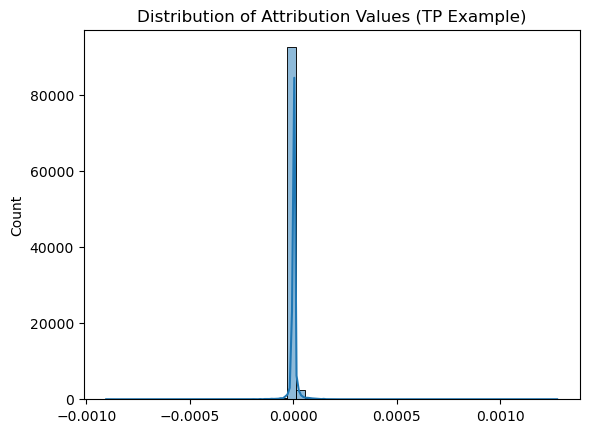

In [85]:
# produce a histogram ploot of values in overall_list
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(overall_list[1][0].flatten(), bins=50, kde=True)
# log y axis
#plt.yscale('log')
plt.title('Distribution of Attribution Values (TP Example)')

In [145]:
default_cmap = LinearSegmentedColormap.from_list('custom red',
                                                 [(0, '#ffffff'),
                                                  (1, "#08ff4a")], N=256)


In [157]:
idx = dset.df[(dset.df['accession'] == 19390745) & (dset.df['mipview'] == 'cor')].index[0]
idx = dset.df[(dset.df['accession'] == 6487513) & (dset.df['mipview'] == 'cor')].index[0]

rr = dset[idx][0] # get the tensor
rgb_img = dataset_tensor_to_rgb_img(rr) # convert to rgb image

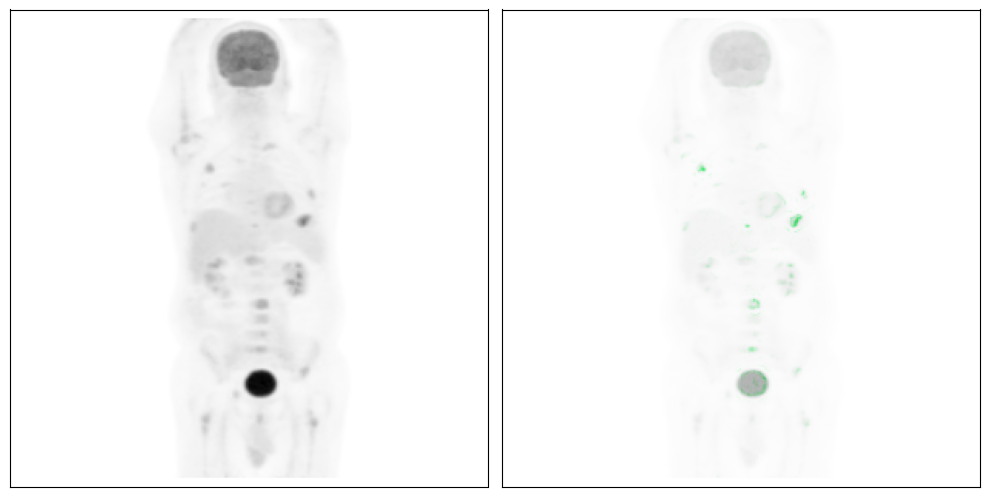

In [ ]:
import PIL
from PIL import Image
fig, axs = plt.subplots(1, 2, figsize=(10, 6))
axs[0].imshow(255-rgb_img, cmap='gray')
axs[1].imshow(255-rgb_img, cmap='gray')
axs[1].imshow(np.clip(overall_list[0][0], a_min=0, a_max=None), cmap = default_cmap, alpha = 0.7)
# disable tick labels
for ax in axs:
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
fig.savefig('/gpfs/home/kn2347/MARS/tmp_sav/v1.png', dpi=600)

In [26]:
layer_idx = 4
with warnings.catch_warnings():
    # for a single seed, do all interp's
    save_dir = f'{rt}/{dataset_type}/interpretability/'
    
    for i, row in dfo_prep.iterrows():
        accession_id = row['accession']
        label_number = row['label']
        lab_type = row['type']
        true_label = row['true_label']

        #for method in ['IntegratedGradients', 'GuidedGradCam', 'Occlusion', 'GuidedBackprop', 'pytorch-gradcam']:
        #for method in ['IntegratedGradients', 'Occlusion', 'GuidedBackprop', 'pytorch-gradcam']:
        for method in ['IntegratedGradients', 'Occlusion', 'GuidedBackprop']:
        #for method in ['IntegratedGradients', 'Occlusion', 'GuidedBackprop']:
        #for method in ['GuidedBackprop']:

            new_path = os.path.join(save_dir, lab_type, str(accession_id), f'{method}_explain{label_number}.png')
            os.makedirs(os.path.dirname(new_path), exist_ok=True)
            
            fig, axs = plt.subplots(2,2, figsize = (10,10))

            # show original image
            
            print(f"Processing {accession_id}, label={true_label}, explaining {label_number}, type {lab_type}, method {method}")
            model_to_use = models_list[-1]
            target_layer = model_to_use.features[layer_idx][2].conv2
            if uses_mipview:
                cor_img, cor_attribution, cor_prob = calculate_interpretability_for_study(accession_id, 'cor', label_number, type=method, layer_to_iterate=target_layer, device='cuda',
                    model_to_use=model_to_use, model_idx = range(10))
                sag_img, sag_attribution, sag_prob  = calculate_interpretability_for_study(accession_id, 'sag', label_number, type=method, layer_to_iterate=target_layer, device='cuda',
                    model_to_use=model_to_use, model_idx = range(10))
                visualize_interpretability(cor_img, cor_attribution, cor_prob, fig, axs[0,1], type=method, alpha=0.7)
                visualize_interpretability(sag_img, sag_attribution, sag_prob, fig, axs[1,1], type=method, alpha=0.7)
            else:
                cor_img, cor_attribution, cor_prob = calculate_interpretability_for_study(accession_id, None, label_number, type=method, layer_to_iterate=target_layer, device='cuda',
                    model_to_use=model_to_use, model_idx = range(10))
                visualize_interpretability(cor_img, cor_attribution, cor_prob, fig, axs, type=method, alpha=0.7, i1=(0,1), i2=(1,1))
                sag_img = cor_img[cor_img.shape[0]//2 : -1,:,:]
                cor_img = cor_img[:cor_img.shape[0]//2,:,:]
                sag_prob = cor_prob
                
            axs[0,0].imshow(cor_img)
            axs[1,0].imshow(sag_img)

            fig.suptitle(f'{method} - accession {accession_id}, label={true_label}, explaining {label_number}, corprob= {cor_prob:.2f}, sagprob= {sag_prob:.2f}')

            #fig.savefig(new_path, dpi=600)

            for ii in range(2):
                for jj in range(2):
                    axs[ii, jj].axis('off')
            fig.savefig(new_path, dpi=600)
            plt.close()


Processing 9901784, label=1, explaining 1, type TP, method IntegratedGradients
Processing 9901784, label=1, explaining 1, type TP, method Occlusion
Processing 9901784, label=1, explaining 1, type TP, method GuidedBackprop


/gpfs/home/kn2347/.conda/envs/myeloma6/lib/python3.10/site-packages/captum/attr/_core/guided_backprop_deconvnet.py:64: UserWarning: Setting backward hooks on ReLU activations.The hooks will be removed after the attribution is finished
  warnings.warn(


Processing 9556655, label=1, explaining 1, type TP, method IntegratedGradients
Processing 9556655, label=1, explaining 1, type TP, method Occlusion
Processing 9556655, label=1, explaining 1, type TP, method GuidedBackprop


/gpfs/home/kn2347/.conda/envs/myeloma6/lib/python3.10/site-packages/captum/attr/_core/guided_backprop_deconvnet.py:64: UserWarning: Setting backward hooks on ReLU activations.The hooks will be removed after the attribution is finished
  warnings.warn(


Processing 43026509, label=1, explaining 1, type TP, method IntegratedGradients
Processing 43026509, label=1, explaining 1, type TP, method Occlusion
Processing 43026509, label=1, explaining 1, type TP, method GuidedBackprop


...

/gpfs/home/kn2347/.conda/envs/myeloma6/lib/python3.10/site-packages/captum/attr/_core/guided_backprop_deconvnet.py:64: UserWarning: Setting backward hooks on ReLU activations.The hooks will be removed after the attribution is finished
  warnings.warn(


Processing 8645606, label=1, explaining 0, type TP, method IntegratedGradients
Processing 8645606, label=1, explaining 0, type TP, method Occlusion
Processing 8645606, label=1, explaining 0, type TP, method GuidedBackprop


/gpfs/home/kn2347/.conda/envs/myeloma6/lib/python3.10/site-packages/captum/attr/_core/guided_backprop_deconvnet.py:64: UserWarning: Setting backward hooks on ReLU activations.The hooks will be removed after the attribution is finished
  warnings.warn(


Processing 6835621, label=0, explaining 1, type TN, method IntegratedGradients
Processing 6835621, label=0, explaining 1, type TN, method Occlusion
Processing 6835621, label=0, explaining 1, type TN, method GuidedBackprop


/gpfs/home/kn2347/.conda/envs/myeloma6/lib/python3.10/site-packages/captum/attr/_core/guided_backprop_deconvnet.py:64: UserWarning: Setting backward hooks on ReLU activations.The hooks will be removed after the attribution is finished
  warnings.warn(


Processing 9901784, label=1, explaining 1, type TP, method IntegratedGradients
Seed 0


KeyError: 'mipview'

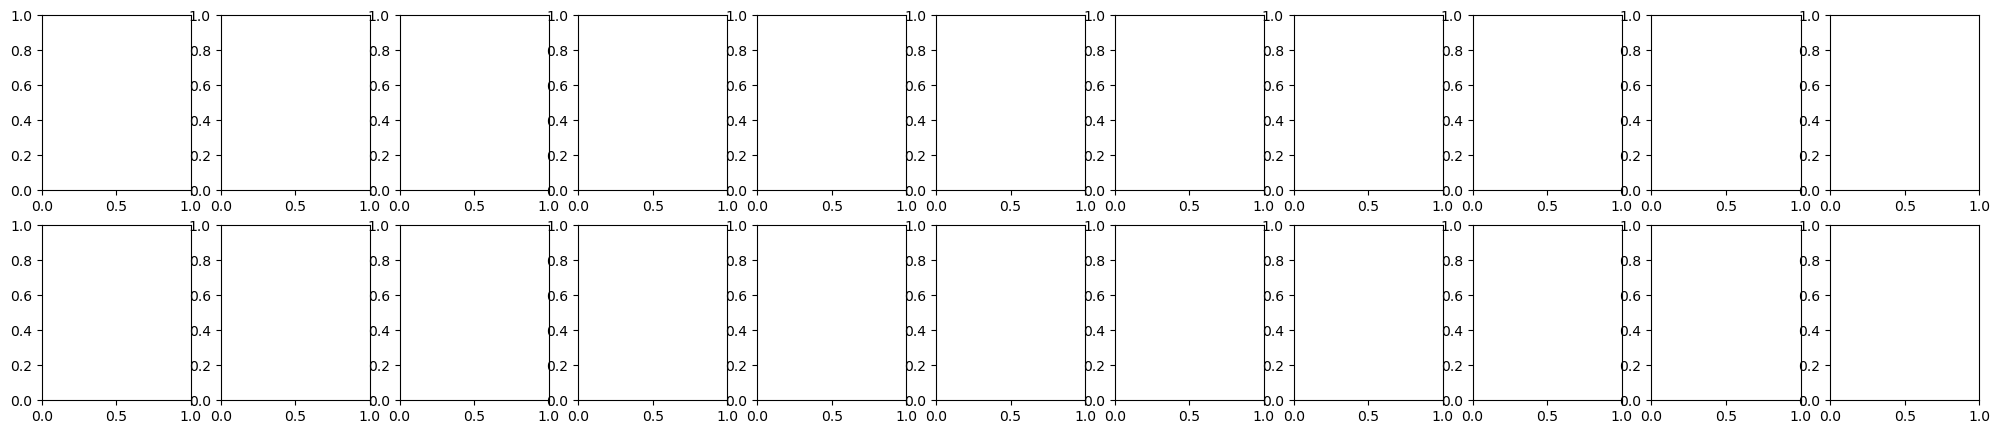

In [ ]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    # compare interps across seeds
    layer_idx=5
    save_dir = f'{rt}/{dataset_type}/interpretability_compare_seeds/'
    for i, row in dfo_prep.iterrows():
        accession_id = row['accession']
        label_number = row['label']
        lab_type = row['type']
        true_label = row['true_label']

        for method in ['IntegratedGradients', 'Occlusion', 'GuidedBackprop']:
        #for method in ['GuidedBackprop']:
            new_path = os.path.join(save_dir, lab_type, str(accession_id), f'{method}_explain{label_number}.png')
            os.makedirs(os.path.dirname(new_path), exist_ok=True)
            
            fig, axs = plt.subplots(2,11, figsize = (25,5))
            print(f"Processing {accession_id}, label={true_label}, explaining {label_number}, type {lab_type}, method {method}")
            sag_probs = []
            cor_probs = []
            
            for seed_idx, model_to_use in enumerate(models_list):
                print(f'Seed {seed_idx}')

                if uses_mipview:
                    cor_img, cor_attribution, cor_prob = calculate_interpretability_for_study(accession_id, 'cor', label_number, type=method, layer_to_iterate=target_layer, device='cuda',
                        model_to_use=model_to_use, model_idx = [seed_idx])
                    sag_img, sag_attribution, sag_prob = calculate_interpretability_for_study(accession_id, 'sag', label_number, type=method, layer_to_iterate=target_layer, device='cuda',
                        model_to_use=model_to_use, model_idx = [seed_idx])
                    visualize_interpretability(cor_img, cor_attribution, cor_prob, fig, axs[0,seed_idx+1], type=method, alpha=0.7)
                    visualize_interpretability(sag_img, sag_attribution, sag_prob, fig, axs[1,seed_idx+1], type=method, alpha=0.7)
                    
                    cor_probs.append(cor_prob)
                    sag_probs.append(sag_prob)
                    
                else:
                    cor_img, cor_attribution, cor_prob = calculate_interpretability_for_study(accession_id, None, label_number, type=method, layer_to_iterate=target_layer, device='cuda',
                        model_to_use=model_to_use, model_idx = [seed_idx])
                    visualize_interpretability(cor_img, cor_attribution, cor_prob, fig, axs[0,seed_idx+1], type=method, alpha=0.7)
                    sag_img = cor_img[cor_img.shape[0]//2 : -1,:,:]
                    cor_img = cor_img[:cor_img.shape[0]//2,:,:]
                    cor_probs.append(cor_prob)
                    sag_probs.append(cor_prob)
                
                if seed_idx == 0:
                    axs[0,0].imshow(cor_img)
                    axs[1,0].imshow(sag_img)
            
            for ii in range(2):
                for jj in range(11):
                    axs[ii, jj].axis('off')

            # round all floats in cor_probs to 2 places
            cor_probs = [float(round(prob, 2)) for prob in cor_probs]
            sag_probs = [float(round(prob, 2)) for prob in sag_probs]
            if uses_mipview:
                fig.suptitle(f'{method} - accession {accession_id}, label={true_label}, explaining {label_number}, corprobs (mean {np.mean(cor_probs):.2f})= {cor_probs}, sagprobs (mean {np.mean(sag_probs):.2f})= {sag_probs}')
            else:
                probs = cor_probs
                fig.suptitle(f'{method} - accession {accession_id}, label={true_label}, explaining {label_number}, probs (mean {np.mean(probs):.2f})= {probs}')
            fig.tight_layout()
            fig.savefig(new_path, dpi=600)
            
            #fig.suptitle(f'{method} - accession {accession_id}, label={true_label}, explaining {label_number}, corprob= {cor_prob:.2f}, sagprob= {sag_prob:.2f}')
        '''
            fig.show()
            #fig.savefig(new_path, dpi=600)

            
            #fig.savefig(new_path, dpi=600)
        '''